# Laboratorio guiado: RNN vs LSTM vs GRU con datos de yfinance
Objetivo: predecir el precio de cierre del día siguiente usando una ventana
de los últimos N días, y comparar tres arquitecturas recurrentes.

Completa cada `TODO`. Al final responde las preguntas de discusión.
AVISO: es un ejercicio académico, NO es una recomendación de inversión.

Completen sus nombres acá:

* Manuel Posada - 2220241121
* Ana María Tique - 2220261069
* Yaritxa Duarte - 2220241061

In [ ]:
!pip install -q yfinance tensorflow scikit-learn matplotlib   # necesario en Colab

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, GRU, Dense, Input
from tensorflow.keras.callbacks import EarlyStopping
import tensorflow as tf

np.random.seed(42)
tf.random.set_seed(42)

## Paso 1. Elige tu activo
| Categoría | Tickers |
|---|---|
| Acciones tecnología | AAPL, MSFT, GOOGL, AMZN, NVDA, META, TSLA |
| Acciones tradicionales | KO, PEP, JNJ, WMT, JPM, XOM, DIS |
| ETFs / índices | SPY, QQQ, DIA, GLD, EEM |
| Criptomonedas | BTC-USD, ETH-USD, SOL-USD |
| Divisas | EURUSD=X, USDCOP=X, GBPUSD=X |
| Materias primas | GC=F (oro), CL=F (petróleo), SI=F (plata) |
| Colombia / Latam | EC (Ecopetrol ADR), CIB (Bancolombia ADR), ILF (ETF Latam) |

In [ ]:
TICKER = "NVDA"        # ticker elegido
START  = "2018-01-01"
END    = "2025-12-31"

## Paso 2. Descarga y exploración

(2010, 5)
Price          Close      High       Low      Open     Volume
Date                                                         
2018-01-02  4.917026  4.920726  4.797400  4.828971  355616000
2018-01-03  5.240637  5.270975  5.025555  5.034188  914704000
2018-01-04  5.268262  5.378269  5.246063  5.321786  583268000
2018-01-05  5.312905  5.350150  5.206351  5.283060  580124000
2018-01-08  5.475696  5.549692  5.391341  5.436232  881216000


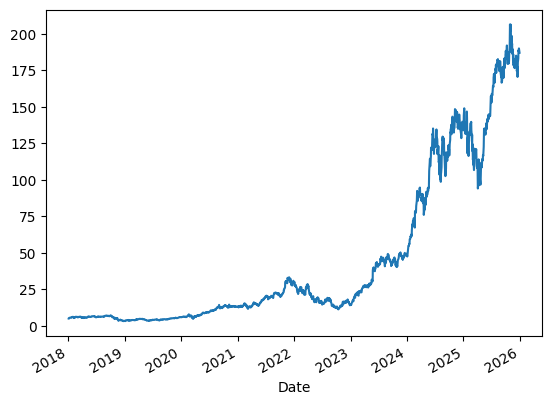

In [ ]:
df = yf.download(TICKER, start=START, end=END, auto_adjust=True, progress=False)
df.columns = df.columns.get_level_values(0)   # aplana columnas multinivel
print(df.shape)
print(df.head())
df['Close'].plot()
plt.show()



# Gráfica del precio de cierre ('Close') a lo largo del tiempo (línea df['Close'].plot() de arriba)

## Paso 3. Preparación de datos
Importante: el escalador se ajusta SOLO con entrenamiento (evita data leakage)
y NO se mezclan los datos (es una serie temporal).

In [ ]:
close = df[['Close']].values            # forma (n, 1)
WINDOW = 90                             # días de historia que ve el modelo
TRAIN_FRAC = 0.8                        #tomamos el 80% de los datos para entrenar el modelo


split = int(len(close) * TRAIN_FRAC)    #Encuentra la posición exacta donde termina el entrenamiento (el ultimo dato del 0.8 del train)

scaler = MinMaxScaler()
# ajusta el scaler solo con close[:split] y transforma TODA la serie

scaler.fit(close[:split])               #El scaler aprende el mínimo y máximo HASTA el día del split usando un rango de 0 a 1
scaled = scaler.transform(close)        #Transforma TODOS los días de la serie usando esa escala aprendida



def make_windows(data, window):
    #- X: Toma un grupo de datos.
    #- y: guarda el precio al final de los datos.
    X, y = [], []
    for i in range(window, len(data)):
        # X toma los 'window' valores anteriores; y es el valor actual
        X.append(data[i - window:i])
        y.append(data[i])
    return np.array(X), np.array(y)

X, y = make_windows(scaled, WINDOW)

# Separa en train/test respetando el orden temporal.
# Como X empieza en el día WINDOW, el corte es (split - WINDOW)
cut = split - WINDOW
X_train, y_train = X[:cut], y[:cut]
X_test,  y_test  = X[cut:], y[cut:]

print("X_train:", X_train.shape, "| X_test:", X_test.shape)  # (muestras, WINDOW, 1)

X_train: (1518, 90, 1) | X_test: (402, 90, 1)


Durante el entrenamiento, en cada época la red recorre las 1518 ventanas de entrenamiento del ejercicio: “te doy 90 días, dime el siguiente”. Con `validation_split=0.1` separa el 10% final (las ventanas más recientes) para validar y usa el resto para ajustar los pesos según el error. Después, con las 402 ventanas de test, se mide qué tan bien predice sobre días que el modelo no conocía.

## Paso 4. Construye los tres modelos
Usa la MISMA arquitectura (1 capa recurrente de 32 unidades + Dense(1))
cambiando solo el tipo de capa. Así la comparación es justa.

In [ ]:
def build_model(layer_class, window=WINDOW, units=32):
    model = Sequential([
        Input(shape=(window, 1)),
        # Capa recurrente recibida en layer_class con 'units' neuronas
        layer_class(units),
        # Capa Dense con 1 neurona de salida
        Dense(1),
    ])
    model.compile(optimizer="adam", loss="mse")
    return model

models = {
    "RNN":  build_model(SimpleRNN),
    "LSTM": build_model(LSTM),
    "GRU":  build_model(GRU),
}

for name, m in models.items():
    print(name, "-> parámetros:", m.count_params())

RNN -> parámetros: 1121
LSTM -> parámetros: 4385
GRU -> parámetros: 3393


Los tres modelos dan números de parámetros distintos porque cada arquitectura maneja su memoria con un número diferente de “reglas”, y cada regla trae su propio juego de pesos que la red tiene que aprender. Los tres tienen la misma capa de 32 unidades; lo que cambia es cuán sofisticado es el método.

La RNN solo mezcla el dato nuevo con la memoria anterior y produce la memoria nueva, por eso tiene solo 1121 parámetros. En cambio, la GRU añade compuertas que deciden qué olvidar y qué actualizar y maneja tres juegos de pesos (3393 parámetros). La LSTM es la más completa: tiene tres compuertas más el cálculo de la memoria nueva, o sea cuatro juegos de pesos (4385 parámetros).

Más reglas significa más pesos, y más pesos significa un modelo más flexible y con memoria más potente, pero en principio también más costoso de entrenar (los tiempos reales se miden en el Paso 8, complemento). Lo que hemos visto hasta ahora es solo el tamaño de los modelos, no qué tan bien predicen. Todavía no los hemos entrenado, así que no sabemos cuál da mejores resultados.

## Paso 5. Entrenamiento


Entrenando RNN...

Entrenando LSTM...

Entrenando GRU...


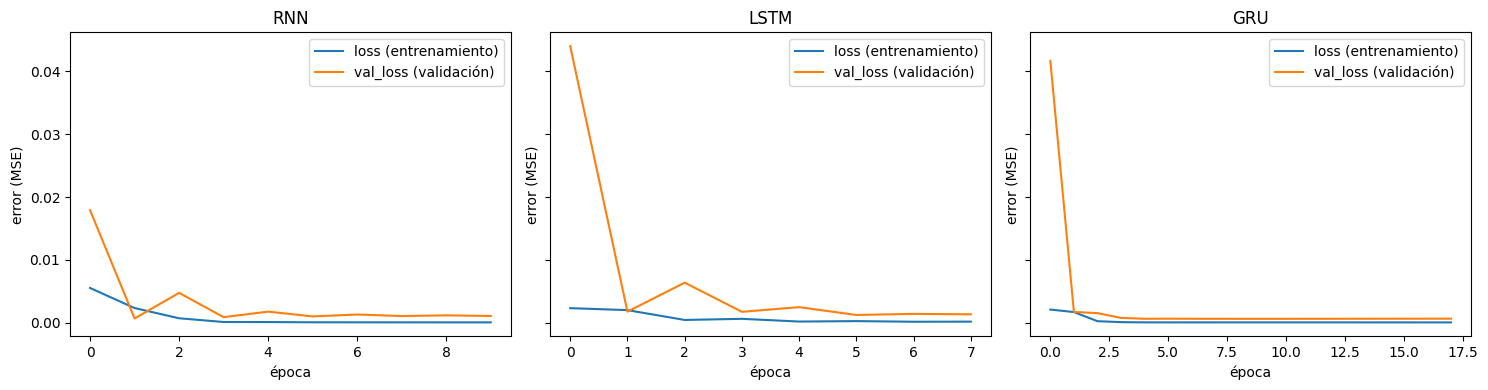

In [ ]:
early_stop = EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
histories = {}

for name, model in models.items():
    print(f"\nEntrenando {name}...")
    # Entrenamiento con model.fit usando: epochs=50, batch_size=32,
    # validation_split=0.1, shuffle=False, callbacks=[early_stop], verbose=0
    histories[name] = model.fit(
      X_train, y_train,
      epochs=50,
      batch_size=32,
      validation_split=0.1,
      shuffle=False,
      callbacks=[early_stop],
      verbose=0)

# Curva de pérdida (loss y val_loss) de cada modelo
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (name, h) in zip(axes, histories.items()):
    ax.plot(h.history["loss"], label="loss (entrenamiento)")
    ax.plot(h.history["val_loss"], label="val_loss (validación)")
    ax.set_title(name)
    ax.set_xlabel("época")
    ax.set_ylabel("error (MSE)")
    ax.legend()
plt.tight_layout()
plt.show()

Por el momento no se puede decir cuál es el mejor modelo: estas curvas corresponden solo a los datos del 80% de entrenamiento (entrenamiento y validación), y el test viene después. Analicemos cada gráfica:

**RNN**: EarlyStopping la detuvo en ≈ 10 épocas. Su val_loss empezó en ≈ 0.018, tuvo picos en las épocas 2 y 4 y luego se estabilizó cerca de 0.001.

**LSTM**: se detuvo en ≈ 8 épocas. Su val_loss partió del valor más alto de los tres (≈ 0.044), cayó casi a cero en la época 1, subió a ≈ 0.006 en la época 2 y después se estabilizó.

**GRU**: fue la que más entrenó, ≈ 18 épocas. Su val_loss partió de ≈ 0.042, bajó a ≈ 0.002 en la época 1 y desde la época ≈ 4 quedó plana, sin picos.

**Sobreajuste**: en ninguno de los tres se ve, porque loss (≈ 0.0001) y val_loss (≈ 0.001) terminan muy bajos y val_loss no sube al final.

**Advertencia**: un val_loss tan bajo no garantiza buen desempeño en test. La validación es el último 10% del entrenamiento, con precios dentro del rango que conoce el escalador, mientras que el test llega a precios mucho más altos. Esto se ve en el Paso 6, donde el error en test es mucho mayor.

**Conclusión parcial**: las tres redes convergen en pocas épocas (8 a 18) y la GRU fue la más estable una vez convergió. Con una sola corrida no se puede afirmar que una aprenda más rápido que otra; cuál predice mejor se define evaluando en el conjunto de test.

## Paso 6. Evaluación
Comparamos contra un modelo ingenuo (baseline): "mañana = hoy".
Si tu red no supera al baseline, ¡no está aportando nada!

In [ ]:
def to_price(arr):
    return scaler.inverse_transform(arr.reshape(-1, 1)).ravel()  #devolvemos los valores del rango de 0 a 1 a los precios reales para ver como se mide el error en dinero

y_true = to_price(y_test)
results, preds = {}, {}

# Baseline ingenuo: el valor anterior de cada y_test
# Baseline con los precios del día anterior
# (el último valor de cada ventana de X_test es X_test[:, -1, 0])


naive_pred = to_price(X_test[:, -1, 0])
results["Baseline"] = {
    "RMSE": np.sqrt(mean_squared_error(y_true, naive_pred)),
    "MAE":  mean_absolute_error(y_true, naive_pred),
}

for name, model in models.items():
    # Predice sobre X_test y conviértelo a precio real con to_price
    p = to_price(model.predict(X_test, verbose=0))
    preds[name] = p
    results[name] = {
        "RMSE": np.sqrt(mean_squared_error(y_true, p)),
        "MAE":  mean_absolute_error(y_true, p),
    }

print(pd.DataFrame(results).T.round(3))

            RMSE     MAE
Baseline   4.189   3.162
RNN       13.033  11.240
LSTM      55.854  53.433
GRU       10.355   8.633


aqui medimos qué tan bien predice cada modelo en el conjunto de test, los 402 días que ninguno vio, y lo compara contra una predicción “tonta”: decir que mañana el precio será igual que hoy.

## Paso 7. Visualización: predicción vs precio real

Gráfica de `y_true` contra la predicción de cada modelo en el conjunto de test, en una sola figura y con un zoom a los últimos 60 días.

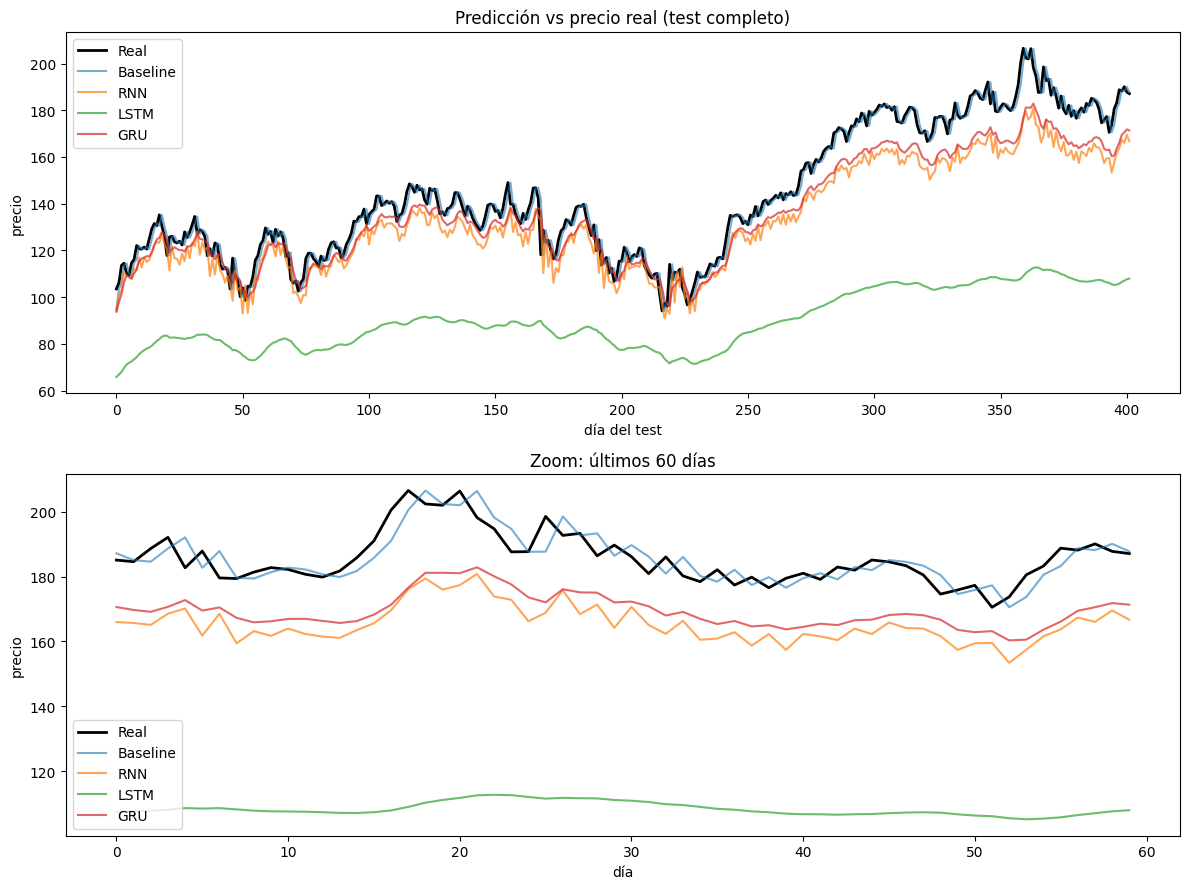

In [ ]:
# Gráfica de y_true vs. la predicción de cada modelo en el conjunto de test
# (una sola figura, con leyenda). Haz también un zoom a los últimos 60 días.
fig, axes = plt.subplots(2, 1, figsize=(12, 9))

# Figura completa (todo el conjunto de test)
axes[0].plot(y_true, label="Real", color="black", linewidth=2)
axes[0].plot(naive_pred, label="Baseline", alpha=0.6)
for name, p in preds.items():
    axes[0].plot(p, label=name, alpha=0.7)
axes[0].set_title("Predicción vs precio real (test completo)")
axes[0].set_xlabel("día del test")
axes[0].set_ylabel("precio")
axes[0].legend()

# Zoom a los últimos 60 días
axes[1].plot(y_true[-60:], label="Real", color="black", linewidth=2)
axes[1].plot(naive_pred[-60:], label="Baseline", alpha=0.6)
for name, p in preds.items():
    axes[1].plot(p[-60:], label=name, alpha=0.7)
axes[1].set_title("Zoom: últimos 60 días")
axes[1].set_xlabel("día")
axes[1].set_ylabel("precio")
axes[1].legend()

plt.tight_layout()
plt.show()

Ninguna de las tres redes neuronales recurrentes logró superar al baseline aplicado a la acción de NVIDIA (NVDA). Este modelo base, que simplemente replica el precio de cierre del día anterior, obtuvo el menor error (RMSE de 4.189 y MAE de 3.162).

Entre las arquitecturas neuronales, la GRU presentó el mejor desempeño (RMSE de 10.355 y MAE de 8.633), seguida por la RNN (RMSE de 13.033 y MAE de 11.240). La LSTM tuvo el peor comportamiento, con un RMSE de 55.854 y un MAE de 53.433. Que la LSTM, la arquitectura con más parámetros, sea la peor muestra que una arquitectura más compleja no garantiza un mejor rendimiento, aunque con una sola corrida no se puede generalizar (ver Mejora 4).

En la gráfica se observa que la RNN y la GRU reproducen la forma de los movimientos del precio, pero quedan por debajo del precio real, y la brecha crece cuando la acción sube con fuerza. La LSTM queda muy por debajo, como una curva suave que solo sigue la tendencia general. La causa más probable es que los precios de NVDA en el test (hasta ≈ 200) superan por mucho los que el escalador vio en entrenamiento (que terminan cerca de 100): como el scaler se ajustó solo con datos de entrenamiento, los valores nuevos quedan fuera del rango [0, 1] y las redes se quedan cortas al predecir valores altos. Esta explicación es una hipótesis que no aislamos por separado; la Mejora 1 (retornos) la respalda, pero no la demuestra por sí sola. Tampoco podemos explicar por qué la LSTM queda tan por debajo de las demás con estos datos.

## Paso 8 (complemento). Tiempos de entrenamiento y otros activos

Las dos celdas siguientes son **independientes del resto del cuaderno** (traen sus propios imports y funciones). La primera define las funciones y mide el tiempo de entrenamiento; la segunda repite el experimento con otros activos. Sus resultados se usan para responder las preguntas 2 y 5 de abajo.

- **Tiempos (pregunta 2):** se entrena cada arquitectura sobre NVDA con 3 semillas y se mide el tiempo por época, porque el tiempo total depende de cuántas épocas decida usar EarlyStopping. Antes de medir se hace un entrenamiento de calentamiento de 1 época para que la primera arquitectura no cargue con el tiempo de inicialización de TensorFlow.
- **Otros activos (pregunta 5):** se repiten los dos planteamientos del cuaderno (precio y retornos) con tres activos: **SPY** (ETF del índice S&P 500), **USD** (ProShares Ultra Semiconductors, un ETF apalancado 2x del sector de semiconductores; en Yahoo Finance ese ticker no es el dólar) y **BTC-USD** (bitcoin, la criptomoneda; cotiza todos los días, incluidos fines de semana, por lo que su serie tiene más filas que las de los otros activos en el mismo periodo). Todo con 3 semillas por modelo. NVDA, el activo del resto del cuaderno, se usa como referencia con los resultados de las Mejoras 1 y 4.

In [ ]:
# Complemento pregunta 2: tiempo de entrenamiento por arquitectura (NVDA, 1 capa de 32 unidades)
!pip install -q yfinance

import time
import numpy as np
import pandas as pd
import yfinance as yf
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, GRU, Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

W, FRAC = 90, 0.8                                   # misma ventana y misma partición del cuaderno
CAPAS = [("RNN", SimpleRNN), ("LSTM", LSTM), ("GRU", GRU)]

def descargar(ticker):
    d = yf.download(ticker, start="2018-01-01", end="2025-12-31", auto_adjust=True, progress=False)
    d.columns = d.columns.get_level_values(0)
    return d["Close"].values.reshape(-1, 1)

def ventanas(data, w=W):
    X = np.array([data[i - w:i] for i in range(w, len(data))])
    y = np.array([data[i] for i in range(w, len(data))])
    return X, y

def preparar_precio(c):
    sp = int(len(c) * FRAC)
    sc = MinMaxScaler().fit(c[:sp])                 # el escalador solo ve el entrenamiento
    X, y = ventanas(sc.transform(c))
    cut = sp - W
    return X[:cut], y[:cut], X[cut:], y[cut:], sc

def modelo(capa, units=32):
    m = Sequential([Input(shape=(W, 1)), capa(units), Dense(1)])
    m.compile(optimizer="adam", loss="mse")
    return m

def entrenar_uno(m, X, y):
    t0 = time.time()
    h = m.fit(X, y, epochs=50, batch_size=32, validation_split=0.1, shuffle=False, verbose=0,
              callbacks=[EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)])
    return len(h.history["loss"]), time.time() - t0

Xtr, ytr, Xte, yte, sc = preparar_precio(descargar("NVDA"))

filas = []
for seed in [0, 1, 2]:
    for nombre, capa in CAPAS:
        tf.keras.utils.set_random_seed(seed)
        modelo(capa).fit(Xtr[:64], ytr[:64], epochs=1, verbose=0)   # calentamiento (no se mide)
        tf.keras.utils.set_random_seed(seed)
        m = modelo(capa)
        ep, seg = entrenar_uno(m, Xtr, ytr)
        filas.append({"Modelo": nombre, "parámetros": m.count_params(), "semilla": seed,
                      "épocas": ep, "segundos": seg, "segundos por época": seg / ep})

t = pd.DataFrame(filas)
print(t.round(2).to_string(index=False))
print()
print(t.groupby("Modelo", sort=False)[["parámetros", "épocas", "segundos", "segundos por época"]].mean().round(2))

Modelo  parámetros  semilla  épocas  segundos  segundos por época
   RNN        1121        0      50     39.56                0.79
  LSTM        4385        0      16     24.32                1.52
   GRU        3393        0      24     53.66                2.24
   RNN        1121        1      50     37.71                0.75
  LSTM        4385        1      12     19.30                1.61
   GRU        3393        1      22     45.70                2.08
   RNN        1121        2      50     36.19                0.72
  LSTM        4385        2      16     24.95                1.56
   GRU        3393        2      13     26.95                2.07

        parámetros  épocas  segundos  segundos por época
Modelo                                                  
RNN         1121.0   50.00     37.82                0.76
LSTM        4385.0   14.67     22.85                1.56
GRU         3393.0   19.67     42.10                2.13


In [ ]:
# Complemento pregunta 5: mismo experimento con otros activos: ETF (USD, SPY) y cripto (BTC-USD) (precio y retornos, 3 semillas)

ACTIVOS = ["USD", "SPY", "BTC-USD"]
SEEDS = [0, 1, 2]

def experimento(ticker):
    c = descargar(ticker)
    sp = int(len(c) * FRAC)

    # A) Precio como objetivo (igual que el experimento original)
    Xtr, ytr, Xte, yte, sc = preparar_precio(c)
    real = sc.inverse_transform(yte).ravel()
    base = sc.inverse_transform(Xte[:, -1, :]).ravel()               # baseline: mañana = hoy
    a_precio = lambda p: sc.inverse_transform(p.reshape(-1, 1)).ravel()

    # B) Retornos como objetivo (igual que la Mejora 1)
    r = pd.Series(c.ravel()).pct_change().dropna().values.reshape(-1, 1)
    spr = sp - 1                                                      # los retornos tienen un dato menos
    scr = MinMaxScaler().fit(r[:spr])
    Xr, yr = ventanas(scr.transform(r))
    ctr = spr - W
    Xtr_r, ytr_r, Xte_r = Xr[:ctr], yr[:ctr], Xr[ctr:]
    prev = c.ravel()[sp - 1: len(c) - 1]                              # precio de ayer de cada día del test
    assert len(Xte_r) == len(real) and np.allclose(prev, base), "el test no coincide"
    a_precio_r = lambda p: prev * (1 + scr.inverse_transform(p.reshape(-1, 1)).ravel())

    casos = {"Precio": (Xtr, ytr, Xte, a_precio), "Retornos": (Xtr_r, ytr_r, Xte_r, a_precio_r)}
    filas, bases = [], []
    for objetivo, (Xa, ya, Xb, conv) in casos.items():
        bases.append({"Activo": ticker, "Objetivo": objetivo,
                      "RMSE": np.sqrt(mean_squared_error(real, base)), "MAE": mean_absolute_error(real, base)})
        for seed in SEEDS:
            tf.keras.utils.set_random_seed(seed)
            ms = {n: modelo(capa) for n, capa in CAPAS}
            for n, m in ms.items():
                ep, _ = entrenar_uno(m, Xa, ya)
                p = conv(m.predict(Xb, verbose=0))
                filas.append({"Activo": ticker, "Objetivo": objetivo, "Modelo": n, "semilla": seed, "épocas": ep,
                              "RMSE": np.sqrt(mean_squared_error(real, p)), "MAE": mean_absolute_error(real, p)})
        print(ticker, objetivo, "listo")
    return pd.DataFrame(filas), pd.DataFrame(bases)

salidas = [experimento(t) for t in ACTIVOS]
res = pd.concat([s[0] for s in salidas])
bases = pd.concat([s[1] for s in salidas])

print("\n=== RMSE y MAE por activo, objetivo y modelo (media y desviación de 3 semillas) ===")
print(res.groupby(["Activo", "Objetivo", "Modelo"], sort=False)[["RMSE", "MAE"]].agg(["mean", "std"]).round(3))
print("\n=== Baseline 'mañana = hoy' ===")
print(bases.round(3).to_string(index=False))

orden = res.groupby(["Activo", "Objetivo", "Modelo"])["RMSE"].mean().unstack("Modelo")[["RNN", "LSTM", "GRU"]]
orden["orden (mejor < peor)"] = orden.apply(lambda f: " < ".join(f.sort_values().index), axis=1)
print("\n=== Ranking por RMSE medio ===")
print(orden.round(3))

USD Precio listo
USD Retornos listo
SPY Precio listo
SPY Retornos listo
BTC-USD Precio listo
BTC-USD Retornos listo

=== RMSE y MAE por activo, objetivo y modelo (media y desviación de 3 semillas) ===
                              RMSE                  MAE          
                              mean       std       mean       std
Activo  Objetivo Modelo                                          
USD     Precio   RNN         6.852     0.144      5.266     0.400
                 LSTM        7.885     1.628      6.327     1.274
                 GRU         2.864     0.290      2.263     0.230
        Retornos RNN         1.774     0.010      1.283     0.010
                 LSTM        1.756     0.010      1.264     0.006
                 GRU         1.757     0.005      1.266     0.005
SPY     Precio   RNN        34.912     3.693     30.573     3.329
                 LSTM       30.587     9.611     26.614     8.554
                 GRU        11.235     0.959      9.395     0.837
       

### Análisis del complemento

**Tiempos de entrenamiento (pregunta 2).** Promedio de 3 semillas sobre NVDA:

| Modelo | Parámetros | Épocas | Segundos totales | Segundos por época |
|---|---|---|---|---|
| RNN | 1121 | 50.0 | 37.82 | 0.76 |
| LSTM | 4385 | 14.7 | 22.85 | 1.56 |
| GRU | 3393 | 19.7 | 42.10 | 2.13 |

1. **Por época**, el orden es claro y consistente en las tres semillas: la RNN es la más rápida (entre 0.72 y 0.79 s), luego la LSTM (1.52 a 1.61 s) y la GRU es la más lenta (2.07 a 2.24 s). Los rangos no se traslapan: la LSTM tarda cerca de 2 veces lo que la RNN y la GRU cerca de 1.4 veces lo que la LSTM.
2. **En tiempo total** el orden cambia porque depende de cuántas épocas use EarlyStopping: la RNN llegó a las 50 épocas en las tres semillas, la GRU usó entre 13 y 24 y la LSTM entre 12 y 16. Por eso la LSTM fue la más rápida en total (22.85 s, entre 19.3 y 25.0). La RNN (37.82 s) fue muy estable porque siempre agotó las 50 épocas, y la GRU (42.10 s) varió mucho entre semillas (de 27.0 a 53.7 s; en una semilla quedó por debajo de la RNN), así que su diferencia con la RNN en tiempo total no es concluyente.
3. **Más parámetros no significó más tiempo:** la LSTM, que tiene más parámetros, no fue la más lenta ni por época ni en total; por época la más lenta fue la GRU, y el orden por época (RNN, LSTM, GRU) no sigue el orden por parámetros (RNN, GRU, LSTM). Una posible causa, que no investigamos, es la implementación de cada capa en TensorFlow y el hardware de Colab. Son 3 corridas en un solo equipo, así que los tiempos son una referencia y no una medida exacta.
4. El número de épocas de la RNN varía mucho: en el Paso 5 se detuvo en ≈ 10, pero en las 3 semillas de la Mejora 4 y aquí agotó las 50.

**Otros activos (pregunta 5).** RMSE medio ± desviación de 3 semillas; la columna Baseline es “mañana = hoy”. Los resultados de NVDA vienen de las Mejoras 1 y 4 (en retornos, de una sola corrida). El RMSE de BTC-USD está en dólares por bitcoin, por eso sus valores son de miles.

*Precio como objetivo*

| Activo | Baseline | RNN | LSTM | GRU | Orden (mejor a peor) |
|---|---|---|---|---|---|
| NVDA | 4.189 | 37.870 ± 17.382 | 29.369 ± 4.967 | 7.434 ± 0.662 | GRU, LSTM, RNN |
| SPY | 6.039 | 34.912 ± 3.693 | 30.587 ± 9.611 | 11.235 ± 0.959 | GRU, LSTM, RNN |
| USD | 1.729 | 6.852 ± 0.144 | 7.885 ± 1.628 | 2.864 ± 0.290 | GRU, RNN, LSTM |
| BTC-USD | 2034.777 | 14234.421 ± 9118.856 | 14424.509 ± 4249.315 | 6456.169 ± 318.423 | GRU, RNN, LSTM |

*Retornos como objetivo*

| Activo | Baseline | RNN | LSTM | GRU | Orden (mejor a peor) |
|---|---|---|---|---|---|
| NVDA (1 corrida) | 4.189 | 4.368 | 4.302 | 4.301 | GRU y LSTM empatadas, RNN última |
| SPY | 6.039 | 6.211 ± 0.047 | 6.072 ± 0.017 | 6.151 ± 0.025 | LSTM, GRU, RNN |
| USD | 1.729 | 1.774 ± 0.010 | 1.756 ± 0.010 | 1.757 ± 0.005 | LSTM y GRU empatadas, RNN última |
| BTC-USD | 2034.777 | 2131.620 ± 43.022 | 2067.993 ± 7.461 | 2074.991 ± 13.580 | LSTM y GRU empatadas, RNN última |

1. **Con precio como objetivo, la GRU fue la mejor en los cuatro activos**, pero ninguna red se acercó al baseline: la GRU quedó 77.5% por encima en NVDA, 86.0% en SPY, 65.6% en USD y 217.3% en BTC-USD, y la RNN y la LSTM quedaron entre 4.0 y 9.0 veces el RMSE del baseline. Es el mismo patrón en los cuatro, y en BTC-USD es incluso más marcado. Es consistente con la hipótesis del rango de precios del test, que no aislamos por separado en ningún activo.
2. **El orden de la RNN y la LSTM sí cambia con el activo:** en NVDA y SPY la LSTM quedó mejor que la RNN, y en USD y BTC-USD la RNN quedó mejor. Ninguna de esas diferencias es concluyente porque todas son menores que la desviación entre semillas del peor de los dos modelos (NVDA 8.5 contra 17.4; SPY 4.3 contra 9.6; USD 7.885 − 6.852 = 1.03 contra 1.628; BTC-USD 190 contra 9119).
3. **Con retornos todas quedan casi pegadas al baseline**: entre 0.5% y 4.8% por encima en RMSE (el 4.8% es la RNN en BTC-USD), y ninguna lo supera en ningún activo. La única coincidencia con el baseline está en el MAE de la LSTM en SPY (3.982 contra 3.991, una diferencia de 0.009 menor que su desviación de 0.011), que es un empate. En BTC-USD las tres quedan por encima del baseline también en MAE (entre 2.5% y 6.7%).
4. **La RNN quedó última con retornos en los cuatro activos.** Entre la LSTM y la GRU no hay un ganador consistente: en SPY la LSTM es mejor por 0.079 (más que sus desviaciones de 0.017 y 0.025), y en USD, NVDA y BTC-USD quedan empatadas (en BTC-USD la diferencia es de 7.0, menor que sus desviaciones de 7.5 y 13.6).
5. **Lo que más cambia el ranking es el objetivo (precio o retornos), más que el activo.** Con precio la GRU gana en los cuatro; con retornos las tres arquitecturas rinden casi igual que el baseline, tanto en los ETF como en la cripto.

**Limitaciones.** (a) Solo se probó una cripto (BTC-USD), con un solo periodo de test. (b) USD es un ETF apalancado 2x del sector de semiconductores, el sector de NVDA, así que no es independiente de ella. (c) Los cuatro activos comparten aproximadamente el mismo periodo de test, con un mismo régimen de mercado; BTC-USD cotiza también fines de semana, así que tiene más días de entrenamiento y de test que los demás. (d) El RMSE no es comparable en valor absoluto entre activos porque los precios están en escalas distintas; por eso se compara con el baseline de cada uno. (e) Con 3 semillas, las desviaciones son estimaciones aproximadas.

## Paso 8. Preguntas de discusión (responde en una celda de texto)
1. ¿Qué modelo tuvo menor RMSE? ¿Superó al baseline "mañana = hoy"?

2. ¿Cuál tiene más parámetros? ¿Y cuál tardó más en entrenar?
3. Mira el gráfico: ¿la predicción parece un "desfase" de la serie real? ¿Por qué?
4. ¿Por qué es incorrecto usar `shuffle=True` o ajustar el scaler con todos los datos?
5. Repite con otro activo (ej. una cripto vs. un ETF). ¿Cambia el ranking?

## Extensiones opcionales
- Cambia WINDOW (10, 30, 60) y observa el efecto.
- Agrega más variables de entrada (Volume, High, Low) -> input_shape=(WINDOW, n_features).
- Predice retornos diarios (df['Close'].pct_change()) en lugar del precio.
- Apila dos capas recurrentes (return_sequences=True en la primera).
- Entrena cada modelo con 3 semillas distintas y reporta media y desviación.

Respuestas (respuestas para el activo NVDA)

**¿Qué modelo tuvo menor RMSE? ¿Superó al baseline "mañana = hoy"?**

La GRU tuvo el menor RMSE entre las redes (10.355; MAE 8.633), seguida de la RNN (13.033) y la LSTM (55.854). Ninguna superó al baseline "mañana = hoy", que obtuvo el mejor resultado con un RMSE de 4.189 y un MAE de 3.162.

**¿Cuál tiene más parámetros? ¿Y cuál tardó más en entrenar?**

La LSTM tiene más parámetros (4385), luego la GRU (3393) y la RNN (1121), porque la LSTM usa cuatro juegos de pesos, la GRU tres y la RNN uno. Para el tiempo se entrenó cada arquitectura sobre NVDA con 3 semillas (Paso 8, complemento). **En tiempo total, la LSTM fue la más rápida (22.85 s), seguida de la RNN (37.82 s) y la GRU (42.10 s).** Esto depende de cuántas épocas decidió usar EarlyStopping: la RNN llegó a las 50 épocas en las tres semillas, la GRU usó 19.7 en promedio y la LSTM 14.7. La GRU varió mucho entre semillas (de 27.0 a 53.7 s) y en una de ellas quedó por debajo de la RNN, así que su diferencia con la RNN en tiempo total no es concluyente. **Por época, el orden sí es claro: la RNN es la más rápida (0.76 s), luego la LSTM (1.56 s) y la GRU es la más lenta (2.13 s)**, con rangos que no se traslapan entre semillas. Es decir, tener más parámetros no significó tardar más: la LSTM no fue la más lenta ni por época ni en total (por época lo fue la GRU). Los tiempos son de 3 corridas en Colab, así que son una referencia y no una medida exacta.

**Mira el gráfico: ¿la predicción parece un "desfase" de la serie real? ¿Por qué?**

Depende de la curva. El baseline sí es literalmente la serie real corrida un día a la derecha (se ve en el zoom de los últimos 60 días).
En el experimento original, en cambio, las redes no muestran un desfase en el tiempo sino un **desfase de nivel**: la RNN y la GRU repiten la forma de los movimientos pero quedan por debajo del precio real, y la LSTM queda muy por debajo. La explicación más probable, que no aislamos, es que los precios del test superan el rango visto en entrenamiento. El retraso de un día sí aparece cuando las redes predicen retornos (Mejora 1): ahí sus curvas se pegan al baseline y reaccionan un día tarde a cada subida o bajada. Esto ocurre porque el precio de hoy es casi igual al de ayer, así que lo más fácil que puede aprender la red es “el precio de ayer más un cambio pequeño”, y los cambios diarios son muy difíciles de anticipar con solo el historial de cierres.

**¿Por qué es incorrecto usar shuffle=True o ajustar el scaler con todos los datos?**

Usar shuffle=True rompe el orden cronológico, que en una serie de tiempo es esencial: el modelo aprendería con datos futuros para predecir datos pasados, algo imposible en la vida real. Por eso los datos se mantienen en orden temporal. También es incorrecto ajustar el scaler con todos los datos porque el mínimo y el máximo incluirían información del conjunto de test, es decir, del futuro; por eso el scaler se ajusta solo con train.

**Repite con otro activo (ej. una cripto vs. un ETF). ¿Cambia el ranking?**

Se repitió el experimento (precio y retornos, 3 semillas por modelo) con tres activos: dos ETF, SPY (índice S&P 500) y USD (ProShares Ultra Semiconductors, apalancado 2x), y una cripto, BTC-USD, y se comparó con NVDA usando las Mejoras 1 y 4. **El ranking cambia solo en parte, y depende más del objetivo que del activo.**

- **Con precio como objetivo** la GRU fue la mejor en los cuatro activos (RMSE NVDA 7.434, SPY 11.235, USD 2.864, BTC-USD 6456.169), pero ninguna red se acercó al baseline (4.189, 6.039, 1.729 y 2034.777): la GRU quedó entre 66% y 217% por encima, y el mayor margen fue el de la cripto. Lo que cambia es el orden entre las otras dos: en NVDA y SPY fue GRU, LSTM, RNN, y en USD y BTC-USD fue GRU, RNN, LSTM, aunque esas diferencias son menores que la desviación entre semillas (por ejemplo, en USD 7.885 contra 6.852 con una desviación de 1.628 en la LSTM), así que no son concluyentes.
- **Con retornos** las tres arquitecturas quedan casi pegadas al baseline, entre 0.5% y 4.8% por encima en RMSE, y ninguna lo supera en ningún activo. La RNN fue la última en los cuatro. La LSTM y la GRU empatan en NVDA, USD y BTC-USD (en BTC-USD 2067.993 contra 2074.991, con desviaciones de 7.5 y 13.6), y solo en SPY la LSTM es mejor, por 0.079 (LSTM 6.072, GRU 6.151, RNN 6.211), así que no hay un ganador consistente entre ellas.

En resumen: con precio la GRU gana en todos los activos, ETF y cripto, pero pierde contra el baseline por un margen enorme; con retornos las diferencias entre arquitecturas son pequeñas y el precio de hoy sigue siendo el mejor predictor del de mañana. Entre la cripto y los ETF no se ve una diferencia de ranking distinta de la que ya hay entre los ETF; lo que sí es mayor en la cripto es el error relativo al baseline con precio. Como limitaciones, solo se probó una cripto, los cuatro activos comparten aproximadamente el mismo periodo de test y USD es un ETF del sector de NVDA.


# **MEJORAS**

Primero definimos 2 funciones cortas para evitar repetir el mismo bucle de entrenamiento y evaluación en cada sección de mejoras.

In [ ]:
def entrenar(modelos, X_tr, y_tr):
    for name, model in modelos.items():
        h = model.fit(X_tr, y_tr, epochs=50, batch_size=32, validation_split=0.1,
                      shuffle=False, verbose=0,
                      callbacks=[EarlyStopping(monitor="val_loss", patience=8,
                                               restore_best_weights=True)])
        print(name, "-> épocas usadas:", len(h.history["loss"]))

def evaluar(modelos, X_te, a_precio=to_price):
    res, pr = {"Baseline": results["Baseline"]}, {}
    for name, model in modelos.items():
        p = a_precio(model.predict(X_te, verbose=0))
        pr[name] = p
        res[name] = {"RMSE": np.sqrt(mean_squared_error(y_true, p)),
                     "MAE":  mean_absolute_error(y_true, p)}
    print(pd.DataFrame(res).T.round(3))
    return pr

def correr_seeds(build_fn, X_tr, y_tr, X_te, a_precio=to_price):
    filas = []
    for seed in [0, 1, 2]:
        tf.keras.utils.set_random_seed(seed)
        ms = {"RNN": build_fn(SimpleRNN), "LSTM": build_fn(LSTM), "GRU": build_fn(GRU)}
        entrenar(ms, X_tr, y_tr)
        for name, m in ms.items():
            p = a_precio(m.predict(X_te, verbose=0))
            filas.append({"Modelo": name, "semilla": seed,
                          "RMSE": np.sqrt(mean_squared_error(y_true, p)),
                          "MAE":  mean_absolute_error(y_true, p)})
    res = pd.DataFrame(filas)
    print(res.round(3))
    print()
    print(res.groupby("Modelo")[["RMSE", "MAE"]].agg(["mean", "std"]).round(3))
    print("\nBaseline -> RMSE:", round(results["Baseline"]["RMSE"], 3),
          "| MAE:", round(results["Baseline"]["MAE"], 3))
    return res

def graficar(pr, titulo):
    fig, axes = plt.subplots(2, 1, figsize=(12, 9))
    for ax, sl, t in [(axes[0], slice(None), "test completo"), (axes[1], slice(-60, None), "zoom últimos 60 días")]:
        ax.plot(y_true[sl], label="Real", color="black", linewidth=2)
        ax.plot(naive_pred[sl], label="Baseline", alpha=0.6)
        for name, p in pr.items():
            ax.plot(p[sl], label=name, alpha=0.7)
        ax.set_title(f"{titulo} - {t}"); ax.set_xlabel("día"); ax.set_ylabel("precio"); ax.legend()
    plt.tight_layout(); plt.show()

# Mejoras 1. Retornos
Con retornos, la red ya no predice el precio de mañana, sino cuánto cambia el precio respecto a hoy (en porcentaje), y después ese cambio se convierte en su precio original.

In [ ]:
retornos = df['Close'].pct_change().dropna().values.reshape(-1, 1)
split_r = split - 1                               # los retornos tienen un dato menos

scaler_r = MinMaxScaler().fit(retornos[:split_r]) # solo con train
X_r, y_r = make_windows(scaler_r.transform(retornos), WINDOW)

cut_r = split_r - WINDOW
X_train_r, y_train_r = X_r[:cut_r], y_r[:cut_r]
X_test_r = X_r[cut_r:]

# Precio de ayer de los mismos 402 días del test original
prev_r = close.ravel()[np.arange(cut_r, len(X_r)) + WINDOW]
assert np.allclose(prev_r, naive_pred), "el test no coincide con el original"

def a_precio_r(pred):
    ret = scaler_r.inverse_transform(pred.reshape(-1, 1)).ravel()   # vuelve a % de cambio
    return prev_r * (1 + ret)                                       # ayer × (1 + cambio)

print("X_train_r:", X_train_r.shape, "| X_test_r:", X_test_r.shape)  # test: 402

X_train_r: (1517, 90, 1) | X_test_r: (402, 90, 1)


RNN -> épocas usadas: 10
LSTM -> épocas usadas: 22
GRU -> épocas usadas: 50
           RMSE    MAE
Baseline  4.189  3.162
RNN       4.368  3.275
LSTM      4.302  3.255
GRU       4.301  3.230


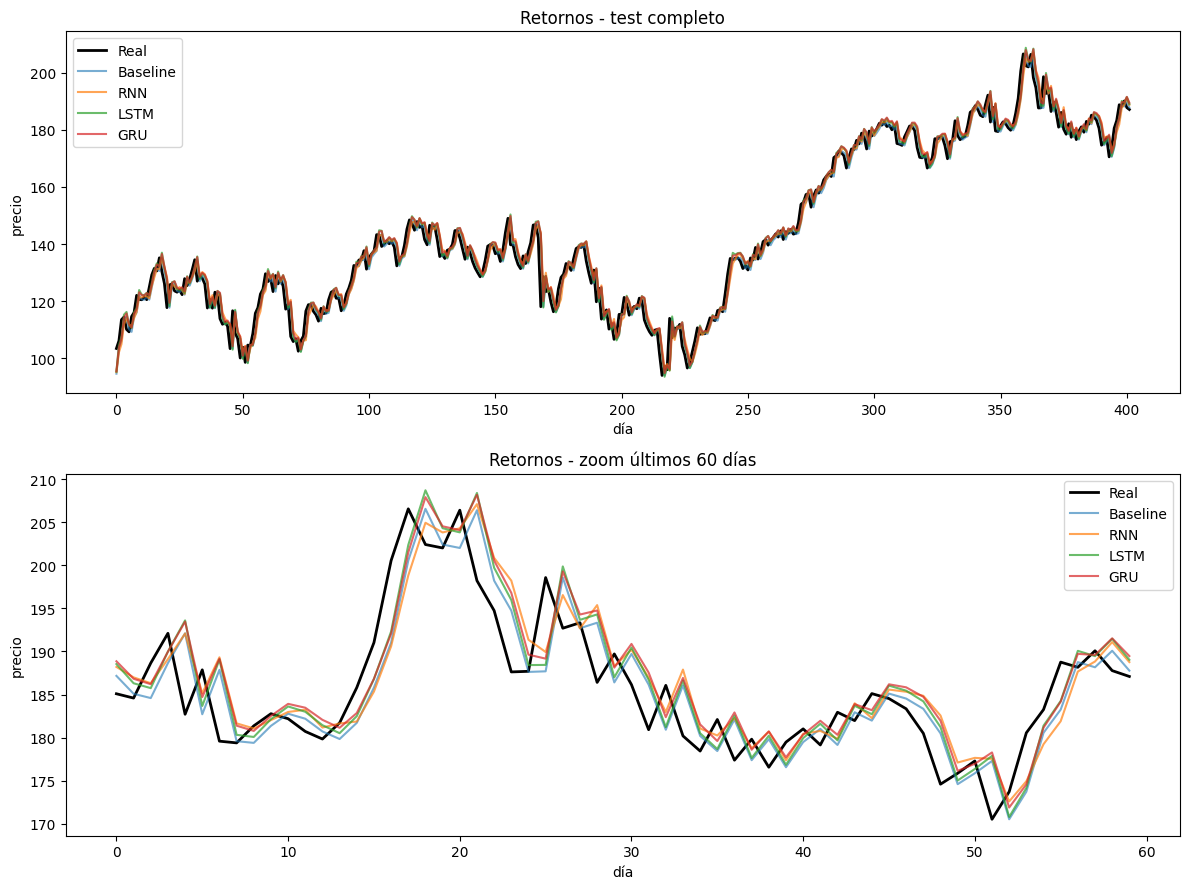

In [ ]:
models_r = {"RNN": build_model(SimpleRNN), "LSTM": build_model(LSTM), "GRU": build_model(GRU)}
entrenar(models_r, X_train_r, y_train_r)
preds_r = evaluar(models_r, X_test_r, a_precio_r)
graficar(preds_r, "Retornos")

Al predecir el cambio porcentual diario en lugar del precio, y manteniendo las demás condiciones del experimento original, el error de las tres redes cayó drásticamente (de 10 a 56 de RMSE a cerca de 4.3) y las predicciones pasaron a seguir de cerca el precio real: RNN 4.368, LSTM 4.302 y GRU 4.301 de RMSE (MAE 3.275, 3.255 y 3.230). Este resultado es consistente con que el mal desempeño inicial se debía a que los precios del test superaban el rango visto en entrenamiento y no a un defecto de las redes. No es una prueba aislada, porque pasar a retornos cambia a la vez el objetivo y la escala.

Aun así, ninguna red superó al baseline ingenuo (RMSE 4.189, MAE 3.162): las mejores quedan ≈ 2.7% por encima en RMSE. En el zoom se ve que las predicciones reproducen la serie con un día de retraso, igual que el baseline. Las diferencias entre RNN, LSTM y GRU son pequeñas (0.07 de RMSE entre la mejor y la peor), del orden de la desviación entre semillas que se mide en el Paso 9 (0.01 a 0.06), y su orden cambia entre ejecuciones, por lo que no permiten afirmar que una arquitectura sea mejor.

# Mejoras 2. Mas variables

Con más variables, la red ya no ve solo el precio de cierre de cada día, sino 4 datos por día: Close, High, Low y Volume. Sigue prediciendo lo mismo (el precio de cierre de mañana), pero con más información de entrada.

In [ ]:
datos = df[['Close', 'High', 'Low', 'Volume']].values
n_features = datos.shape[1]

scaler_v = MinMaxScaler()
scaler_v.fit(datos[:split])               # solo con train, cada columna por separado
datos_s = scaler_v.transform(datos)

X_v, y_v = make_windows(datos_s, WINDOW)
y_v = y_v[:, :1]                          # se predice solo el Close (columna 0)

X_train_v, y_train_v = X_v[:cut], y_v[:cut]
X_test_v,  y_test_v  = X_v[cut:], y_v[cut:]
print("X_train_v:", X_train_v.shape, "| X_test_v:", X_test_v.shape)   # test: 402

X_train_v: (1518, 90, 4) | X_test_v: (402, 90, 4)


RNN -> épocas usadas: 10
LSTM -> épocas usadas: 10
GRU -> épocas usadas: 10
            RMSE     MAE
Baseline   4.189   3.162
RNN       43.701  37.763
LSTM      49.532  43.960
GRU       15.854  13.204


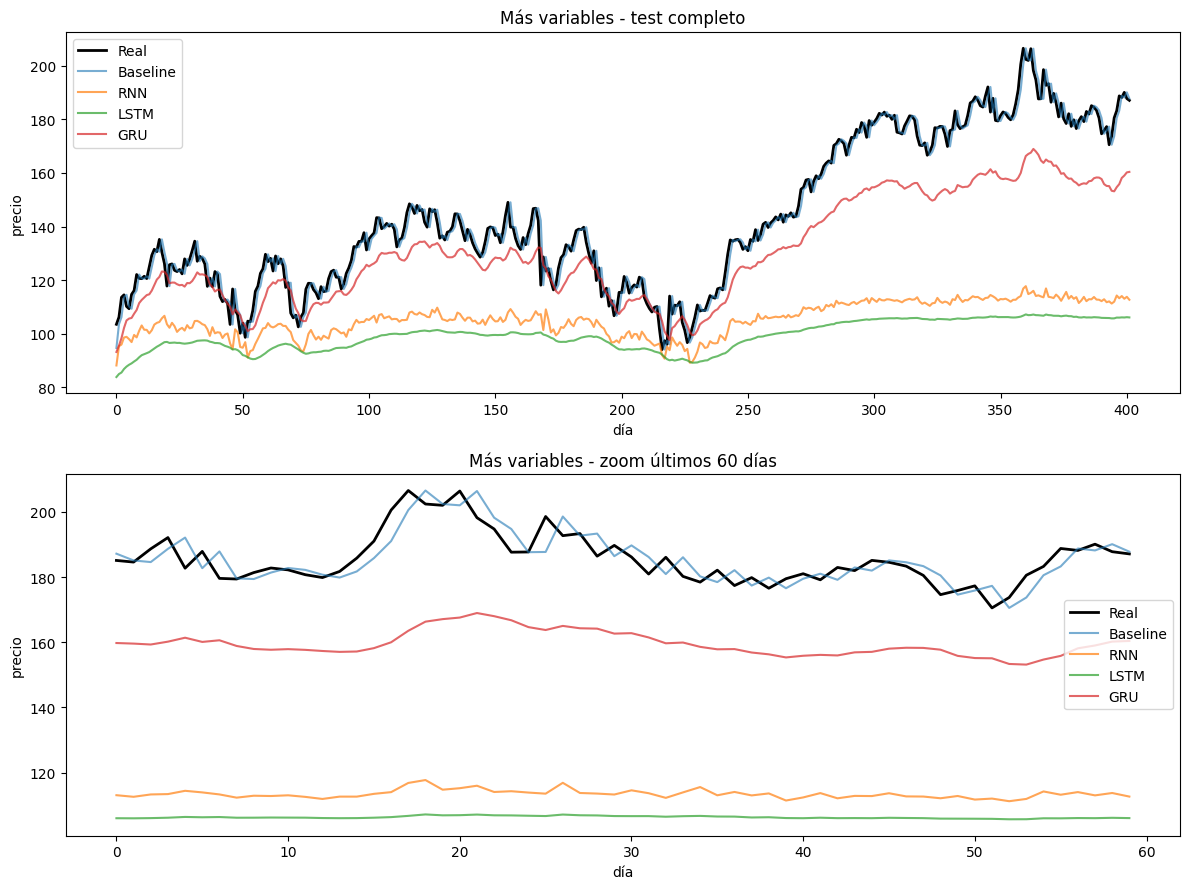

In [ ]:
def build_model_v(layer_class, window=WINDOW, units=32, n_feat=n_features):
    model = Sequential([
        Input(shape=(window, n_feat)),
        layer_class(units),
        Dense(1),
    ])
    model.compile(optimizer="adam", loss="mse")
    return model

models_v = {"RNN": build_model_v(SimpleRNN), "LSTM": build_model_v(LSTM), "GRU": build_model_v(GRU)}
entrenar(models_v, X_train_v, y_train_v)
preds_v = evaluar(models_v, X_test_v)   # to_price sirve: Close usa el mismo min/max
graficar(preds_v, "Más variables")

Con Close, High, Low y Volume, las tres redes siguen quedando por debajo del precio real y sin seguir sus movimientos diarios (RNN y LSTM casi planas, entre 100 y 120; la GRU sigue la forma pero se aleja cada vez más), mientras que el baseline se pega al precio (RMSE 4.19). Frente a una sola variable en esta misma ejecución (RNN 13.03, LSTM 55.85, GRU 10.36), ahora dieron RNN 43.70, LSTM 49.53 y GRU 15.85: la RNN y la GRU empeoraron y la LSTM mejoró algo, pero sigue siendo la peor junto con la RNN. Una posible razón, que no verificamos, es que High y Low están en la misma escala que Close y también salen del rango de entrenamiento, así que las variables adicionales no corrigen ese problema. Como es una sola corrida por modelo y la variación entre semillas es grande, no se puede concluir que las variables adicionales ayuden.

# MEJORA 3. Dos capas recurrentes
Apilar dos capas recurrentes significa que la primera capa procesa la secuencia de 90 días y entrega su estado oculto de cada paso (return_sequences=True), y la segunda capa procesa esa secuencia de estados y produce un resumen final que alimenta a Dense(1). Esto aumenta la capacidad de la red para aprender patrones más complejos, a costa de más parámetros y tiempo de entrenamiento.

RNN -> épocas usadas: 50
LSTM -> épocas usadas: 12
GRU -> épocas usadas: 50
            RMSE     MAE
Baseline   4.189   3.162
RNN       35.386  30.105
LSTM      24.697  20.618
GRU        8.392   6.674


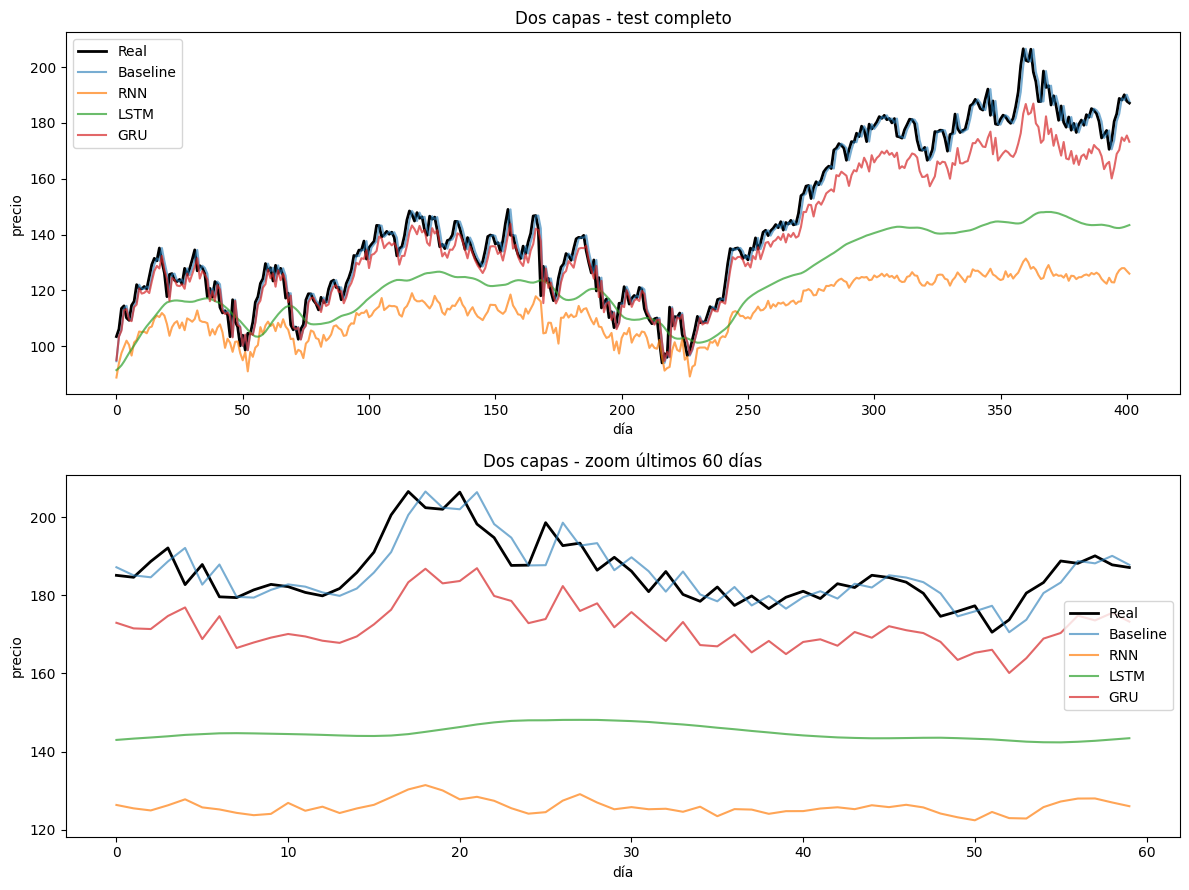

In [ ]:
def build_model_2c(layer_class, window=WINDOW, units=32):
    model = Sequential([
        Input(shape=(window, 1)),
        layer_class(units, return_sequences=True),   # 1ª capa: pasa la memoria de cada día
        layer_class(units),                          # 2ª capa: resume y entrega el final
        Dense(1),
    ])
    model.compile(optimizer="adam", loss="mse")
    return model

models_2c = {"RNN": build_model_2c(SimpleRNN), "LSTM": build_model_2c(LSTM), "GRU": build_model_2c(GRU)}
entrenar(models_2c, X_train, y_train)
preds_2c = evaluar(models_2c, X_test)
graficar(preds_2c, "Dos capas")

Apilar dos capas no resolvió el problema: RNN 35.39, LSTM 24.70 y GRU 8.39, todavía por encima del baseline (4.19). Frente a una capa (13.03 / 55.85 / 10.36), el resultado es mixto: la LSTM (de 55.85 a 24.70) y la GRU (de 10.36 a 8.39) mejoraron, pero la RNN empeoró (de 13.03 a 35.39). En la gráfica, la GRU de dos capas sigue bien la forma del precio pero queda por debajo cuando sube, la LSTM queda como una curva suave muy por debajo y la RNN queda casi plana cerca de 125. La RNN y la GRU llegaron a las 50 épocas sin que EarlyStopping las detuviera, por lo que pudieron quedar sin converger del todo. Es una sola corrida por modelo y la variación entre semillas es del mismo orden (Mejora 4), así que no puede atribuirse el cambio a la arquitectura.

# Mejora 4: 3 semillas
Entrenar cada modelo con varias semillas consiste en repetir el entrenamiento con distintos valores iniciales aleatorios de los pesos, para medir cuánta variación en el resultado se debe al azar.

In [ ]:
res_seeds = correr_seeds(build_model, X_train, y_train, X_test)

RNN -> épocas usadas: 50
LSTM -> épocas usadas: 14
GRU -> épocas usadas: 32
RNN -> épocas usadas: 50
LSTM -> épocas usadas: 16
GRU -> épocas usadas: 50
RNN -> épocas usadas: 50
LSTM -> épocas usadas: 15
GRU -> épocas usadas: 31
  Modelo  semilla    RMSE     MAE
0    RNN        0  57.854  52.782
1   LSTM        0  26.472  22.050
2    GRU        0   8.025   6.653
3    RNN        1  29.495  25.594
4   LSTM        1  26.530  22.392
5    GRU        1   6.718   5.399
6    RNN        2  26.262  22.563
7   LSTM        2  35.105  30.402
8    GRU        2   7.559   6.212

          RMSE             MAE        
          mean     std    mean     std
Modelo                                
GRU      7.434   0.662   6.088   0.636
LSTM    29.369   4.967  24.948   4.726
RNN     37.870  17.382  33.646  16.641

Baseline -> RMSE: 4.189 | MAE: 3.162


Repetir el modelo original con 3 semillas mostró una gran variabilidad: el mismo modelo, entrenado tres veces, da resultados muy distintos. Eso significa que una sola corrida no sirve para sacar conclusiones. Lo que sí podemos decir es:
1. **El resultado depende mucho del azar:** con el mismo modelo y los mismos datos, solo cambiando la semilla, el error varió bastante. El caso más claro es la RNN, que fue de 26 a 58 de RMSE (media 37.87 ± 17.38). También se vio al volver a ejecutar el cuaderno: con el mismo código, la LSTM de una sola corrida pasó de un RMSE de 33.2 en una ejecución anterior a 55.9 en esta.
2. **La GRU fue la mejor y la más estable:** sus 3 semillas quedaron entre 6.7 y 8.0 (media 7.43 ± 0.66), todas mejores que cualquier corrida de los otros modelos. Esto contrasta con la corrida única del Paso 6 (10.36), que quedó fuera de ese rango.
3. **El orden entre RNN y LSTM no es claro:** en la corrida única la RNN (13.03) quedó mejor que la LSTM (55.85), pero en las semillas la LSTM tiene mejor media (29.37 contra 37.87) y sus rangos se traslapan.

En conclusión, ninguna corrida superó al baseline “mañana = hoy” (RMSE 4.19, MAE 3.16), lo que indica que predecir el precio directamente es problemático para las tres arquitecturas. Además, la variabilidad entre semillas muestra que los resultados de una sola corrida no permiten concluir qué arquitectura es mejor, y que las mejoras evaluadas con una sola semilla deben interpretarse con cautela.

# Paso 9. Descomposición Seasonal-Trend (STL) y aplicación de RNN, LSTM y GRU

Hasta ahora las redes recibían el precio (o su retorno) como una sola señal mezclada. Aquí separamos la serie en tendencia, estacionalidad y residuo con STL (*Seasonal-Trend decomposition using LOESS*) y hacemos dos cosas:

1. **Evaluar la descomposición:** ¿cuánta de la variación de NVDA es tendencia, cuánta es estacionalidad y cuánta es ruido (residuo)?
2. **Aplicar RNN, LSTM y GRU usando los componentes** como variables de entrada, y comparar contra la misma red que solo ve el retorno.

**Decisiones de diseño**
- Se descompone el **logaritmo del precio**: así la serie es aditiva (log precio = tendencia + estacionalidad + residuo) y se evita el problema de escala de los precios altos que ya vimos en el experimento original.
- La descomposición de 9.1 usa toda la serie y es **solo descriptiva**: STL suaviza con datos de ambos lados, así que la tendencia de un día usa días futuros.
- Para el modelado de 9.2 se evita ese *leakage*: cada día se calcula una STL **solo con los últimos 504 días hasta ese día** (descomposición causal) y se guarda el último valor de cada componente.
- Se predice el **retorno del día** (como en Mejora 1) y se convierte a precio con el precio de ayer, así que el conjunto de test y el baseline son exactamente los mismos 402 días de antes.
- Como la descomposición necesita 504 días de historia, el entrenamiento de esta sección es más corto (1015 ventanas en vez de 1518). Por eso se compara contra un control con **las mismas fechas de entrenamiento** que solo ve el retorno.
- Se usan 3 semillas por modelo, por lo que vimos en la Mejora 4.

 periodo (días)  fuerza tendencia  fuerza estacional  std estacional / std residuo
              5             0.999              0.000                         0.408
             21             0.999              0.095                         0.493
             63             0.996              0.108                         0.473
            252             0.960              0.000                         0.599


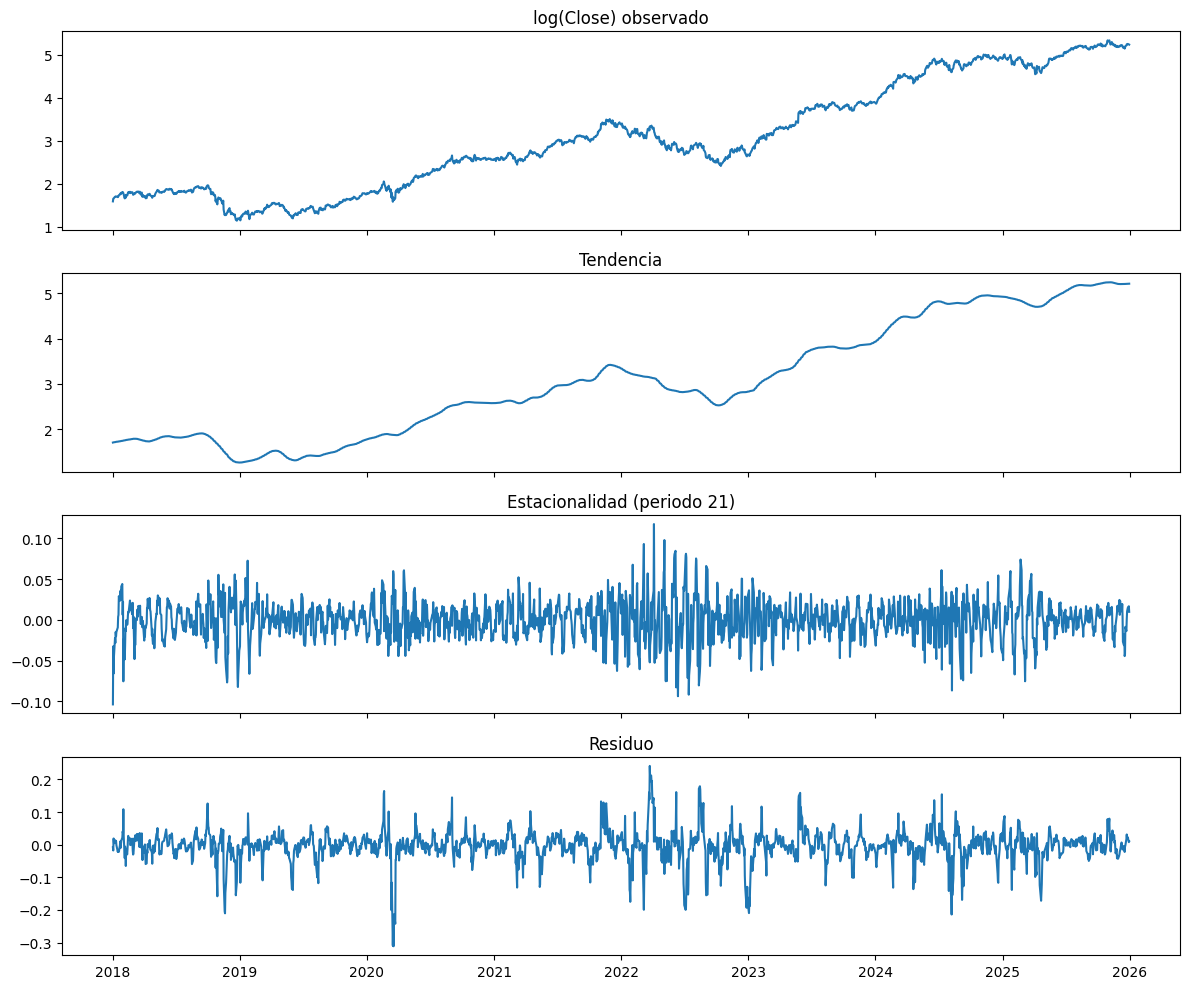

In [ ]:
# 9.1 Evaluar la descomposición STL (descriptiva, sobre toda la serie)
from statsmodels.tsa.seasonal import STL

lc = np.log(df['Close'].values)          # log del precio

def fuerza(res, comp):
    # Fuerza de un componente (Hyndman): 0 = no aporta frente al residuo, 1 = domina
    return max(0.0, 1 - np.var(res.resid) / np.var(comp + res.resid))

# ¿Qué periodo estacional tiene sentido? 5 = semana bursátil, 21 = mes, 63 = trimestre, 252 = año
filas = []
for periodo in [5, 21, 63, 252]:
    r = STL(lc, period=periodo, robust=True).fit()
    filas.append({"periodo (días)": periodo,
                  "fuerza tendencia": fuerza(r, r.trend),
                  "fuerza estacional": fuerza(r, r.seasonal),
                  "std estacional / std residuo": r.seasonal.std() / r.resid.std()})
print(pd.DataFrame(filas).round(3).to_string(index=False))

# Gráfica de la descomposición con periodo mensual (21 días bursátiles)
PERIODO = 21
res_stl = STL(lc, period=PERIODO, robust=True).fit()
fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
for ax, serie, titulo in zip(axes,
        [lc, res_stl.trend, res_stl.seasonal, res_stl.resid],
        ["log(Close) observado", "Tendencia", f"Estacionalidad (periodo {PERIODO})", "Residuo"]):
    ax.plot(df.index, serie)
    ax.set_title(titulo)
plt.tight_layout()
plt.show()

### Análisis de la descomposición (9.1)

**Qué muestran los números.** La tendencia explica casi toda la variación de log(Close): su fuerza es 0.999 con periodos de 5 y 21 días, 0.996 con 63 y 0.960 con 252. La estacionalidad es débil: la mayor fuerza aparece con periodo 63 (0.108) y con 21 (0.095), y con 5 y 252 días es 0.000, es decir, ese componente no explica variación adicional frente al residuo (de hecho se compensa en parte con él). La razón std estacional / std residuo (0.41 a 0.60) no contradice esto: solo mide la amplitud del componente, no cuánto explica. Por eso con periodo 252 es la más alta (0.599) y su fuerza es 0.

**Qué muestran las gráficas.** El log del precio sube de ≈ 1.6 a ≈ 5.3 y la tendencia (curva suave) reproduce ese recorrido, con caídas en 2018-2019 y 2022. El componente estacional oscila con el periodo de 21 días que se le impone, pero su amplitud cambia mucho (es mayor alrededor de 2022 y menor en otros años), lo que sugiere que absorbe parte de la volatilidad más que un patrón de calendario estable; el pico al inicio de la serie es probablemente un efecto de borde. El residuo tiene sus mayores caídas hacia marzo de 2020 (≈ −0.3) y picos positivos en 2022 (≈ +0.24), épocas de alta volatilidad.

**Qué significa.** NVDA entre 2018 y 2025 es una serie dominada por la tendencia, con una estacionalidad mensual o trimestral casi inexistente. Eso no implica que sea predecible: es lo esperable en un precio con deriva. Sí ayuda a entender por qué trabajar con el precio en nivel es problemático (la tendencia lleva el precio a valores que el escalador nunca vio) y por qué el retorno, que en gran parte elimina esa tendencia, funciona mejor. Por eso en 9.2 el objetivo es el retorno y los componentes se calculan de forma causal.

In [ ]:
# 9.2 Componentes STL causales como entradas de las redes
ROLL = 504                                 # cada día se descompone con los últimos 504 días (~2 años)
n = len(close)
log_c = np.log(close.ravel())
ret_log = np.r_[np.nan, np.diff(log_c)]    # retorno logarítmico diario

# Columnas: 0 = retorno del día (también es el objetivo), 1 = cambio de tendencia,
#           2 = componente estacional, 3 = residuo
F = np.full((n, 4), np.nan)
for t in range(ROLL - 1, n):
    r = STL(log_c[t - ROLL + 1: t + 1], period=PERIODO, robust=False).fit()
    F[t] = [ret_log[t], r.trend[-1] - r.trend[-2], r.seasonal[-1], r.resid[-1]]
s0 = ROLL - 1                              # primer día con componentes disponibles

# Escalador ajustado SOLO con las filas de entrenamiento (sin leakage)
sc_d = MinMaxScaler().fit(F[s0:split])
F_s = sc_d.transform(F[s0:])

X_d, y_d = make_windows(F_s, WINDOW)
y_d = y_d[:, :1]                           # se predice solo el retorno (columna 0)

cut_d = split - s0 - WINDOW                # el test empieza en el mismo día que antes
X_train_d, y_train_d = X_d[:cut_d], y_d[:cut_d]
X_test_d = X_d[cut_d:]

prev_d = close.ravel()[split - 1: n - 1]   # precio de ayer de cada día del test
assert len(X_test_d) == len(y_true) and np.allclose(prev_d, naive_pred), "el test no coincide con el original"

def a_precio_d(pred):
    ret = (pred.ravel() - sc_d.min_[0]) / sc_d.scale_[0]   # desescala el retorno logarítmico
    return prev_d * np.exp(ret)                            # ayer × e^retorno

print("X_train_d:", X_train_d.shape, "| X_test_d:", X_test_d.shape)   # test: 402

X_train_d: (1015, 90, 4) | X_test_d: (402, 90, 4)


In [ ]:
# 9.3 Control (solo retorno) vs. retorno + componentes STL, 3 semillas cada uno
print("=== Control: solo retorno ===")
res_ret = correr_seeds(lambda layer: build_model_v(layer, n_feat=1),
                       X_train_d[:, :, :1], y_train_d, X_test_d[:, :, :1], a_precio_d)

print("\n=== Retorno + tendencia + estacionalidad + residuo (STL) ===")
res_stlf = correr_seeds(lambda layer: build_model_v(layer, n_feat=4),
                        X_train_d, y_train_d, X_test_d, a_precio_d)

res_ret["Entrada"] = "Solo retorno"
res_stlf["Entrada"] = "Retorno + STL"
resumen = pd.concat([res_ret, res_stlf]).groupby(["Entrada", "Modelo"])[["RMSE", "MAE"]].agg(["mean", "std"]).round(3)
print("\n=== Resumen comparativo ===")
print(resumen)
print("Baseline -> RMSE:", round(results["Baseline"]["RMSE"], 3), "| MAE:", round(results["Baseline"]["MAE"], 3))

=== Control: solo retorno ===
RNN -> épocas usadas: 10
LSTM -> épocas usadas: 50
GRU -> épocas usadas: 50
RNN -> épocas usadas: 50
LSTM -> épocas usadas: 50
GRU -> épocas usadas: 50
RNN -> épocas usadas: 16
LSTM -> épocas usadas: 25
GRU -> épocas usadas: 50
  Modelo  semilla   RMSE    MAE
0    RNN        0  4.331  3.273
1   LSTM        0  4.310  3.254
2    GRU        0  4.283  3.217
3    RNN        1  4.451  3.398
4   LSTM        1  4.306  3.251
5    GRU        1  4.276  3.209
6    RNN        2  4.378  3.319
7   LSTM        2  4.271  3.215
8    GRU        2  4.299  3.234

         RMSE          MAE       
         mean    std  mean    std
Modelo                           
GRU     4.286  0.012  3.22  0.013
LSTM    4.295  0.022  3.24  0.022
RNN     4.387  0.060  3.33  0.063

Baseline -> RMSE: 4.189 | MAE: 3.162

=== Retorno + tendencia + estacionalidad + residuo (STL) ===
RNN -> épocas usadas: 26
LSTM -> épocas usadas: 50
GRU -> épocas usadas: 50
RNN -> épocas usadas: 18
LSTM -> épocas u

### Análisis del Paso 9: redes con componentes STL

**Resultados (RMSE medio ± desviación en 3 semillas; el baseline tiene RMSE 4.189 y MAE 3.162):**

| Modelo | Solo retorno | Retorno + STL |
|---|---|---|
| RNN | 4.387 ± 0.060 | 4.432 ± 0.080 |
| LSTM | 4.295 ± 0.022 | 4.334 ± 0.010 |
| GRU | 4.286 ± 0.012 | 4.363 ± 0.010 |

1. **Los componentes STL no mejoraron a las redes.** Con la misma ventana, las mismas fechas de entrenamiento y el mismo test, agregar tendencia, estacionalidad y residuo empeoró el RMSE de las tres: GRU +0.077, LSTM +0.039 y RNN +0.045 (el MAE se movió igual, por ejemplo GRU de 3.220 a 3.282). En la GRU y la LSTM el aumento es mayor que la desviación entre semillas; en la RNN queda dentro de ella. Con solo 3 semillas esto es un indicio, no una prueba. Una explicación posible, que no verificamos, es que los componentes se calculan solo con cierres pasados y por eso no aportan información nueva, mientras que tres variables más con ≈ 1000 ventanas de entrenamiento agregan ruido.
2. **El ranking entre arquitecturas no es concluyente.** La RNN quedó última en ambas configuraciones. La GRU y la LSTM difieren en 0.009 en el control y 0.029 con STL, y su orden se invierte, así que no se puede afirmar cuál es mejor.
3. **Ninguna combinación superó al baseline.** La mejor (GRU con solo retorno, 4.286) queda ≈ 2.3% por encima en RMSE y ≈ 1.8% en MAE. Que todos los resultados estén tan cerca del baseline es consistente con que las redes aprenden a predecir un retorno cercano a cero, es decir, “el precio de ayer más un cambio pequeño”.
4. **Comparación con las otras secciones.** Estos errores (≈ 4.3) son parecidos a los de la Mejora 1 (retornos, 4.30 a 4.37) y mucho menores que los de los experimentos con precio. Eso confirma que lo que más influyó fue plantear el problema con retornos y no los componentes ni la arquitectura.
5. **Limitaciones.** (a) Varias LSTM y GRU llegaron a las 50 épocas sin que EarlyStopping las detuviera (por ejemplo, las 3 GRU del control), por lo que pudieron quedar sin converger del todo. (b) El entrenamiento usa 1015 ventanas, un tercio menos que en las secciones anteriores. (c) Los componentes del último día de cada ventana son los menos confiables en STL (efecto de borde). (d) Se probó un solo periodo (21 días) y una sola ventana de descomposición (504 días).

# **Conclusión final**

En este laboratorio comparamos una RNN, una LSTM y una GRU (1 capa de 32 unidades) para predecir el precio de cierre de una acción; elegimos NVDA y usamos ventanas de 90 días. El resultado principal es que **ninguna red superó al baseline “mañana = hoy”** (RMSE 4.189, MAE 3.162), ni en el experimento original, ni en las mejoras, ni con la descomposición STL.

**Experimento original (precio como objetivo).** La GRU fue la mejor (RMSE 10.355), seguida de la RNN (13.033) y la LSTM (55.854). La RNN y la GRU siguieron la forma del precio pero quedaron por debajo, y la LSTM quedó muy por debajo. Una causa probable, que no aislamos por separado, es que el precio del test (hasta ≈ 200) superó el rango visto en entrenamiento (que termina cerca de 100).

**Mejoras (una sola corrida, salvo la última):**
- **Retornos diarios:** fue la única mejora que cambió el resultado de forma drástica. El error bajó a 4.368 (RNN), 4.302 (LSTM) y 4.301 (GRU), y las predicciones se pegaron al precio real con un día de retraso. Esto es consistente con que predecir el precio directamente era lo que más perjudicaba a las redes, aunque aun así no superaron al baseline.
- **Más variables (Close, High, Low, Volume):** no dio una mejora clara (RNN 43.701, LSTM 49.532, GRU 15.854).
- **Dos capas:** resultado mixto (RNN 35.386, LSTM 24.697, GRU 8.392); con una sola corrida por modelo no se puede atribuir a la arquitectura.
- **Variabilidad por semilla:** al repetir el modelo original con 3 semillas, la GRU fue la mejor y la más estable (7.434 ± 0.662), mientras que la LSTM (29.369 ± 4.967) y la RNN (37.870 ± 17.382) se traslaparon. Incluso al re-ejecutar el cuaderno, la LSTM de una sola corrida pasó de 33.2 a 55.9. **Una sola corrida no basta para comparar arquitecturas**, y varias diferencias de las mejoras caen dentro del ruido del entrenamiento.

**Descomposición Seasonal-Trend (Paso 9).** La serie de NVDA está dominada por la tendencia (fuerza 0.999 con periodos de 5 y 21 días) y tiene una estacionalidad débil (0.095 con periodo 21, 0.108 con 63 y 0.000 con 5 y 252); el residuo concentra los picos de volatilidad, como marzo de 2020. Usar tendencia, estacionalidad y residuo (calculados de forma causal) como entradas **no mejoró** a las redes frente a usar solo el retorno: GRU pasó de 4.286 a 4.363, LSTM de 4.295 a 4.334 y RNN de 4.387 a 4.432 de RMSE, todas por encima del baseline. Que la serie tenga una tendencia fuerte no la hace predecible a un día.

**Tiempos y otros activos (Paso 8, complemento).** Al medir el entrenamiento sobre NVDA con 3 semillas, la RNN fue la más rápida por época (0.76 s contra 1.56 s de la LSTM y 2.13 s de la GRU), pero en tiempo total la LSTM fue la más rápida (22.85 s contra 37.82 s de la RNN y 42.10 s de la GRU) porque EarlyStopping la detuvo en menos épocas; tener más parámetros no significó tardar más. Al repetir el experimento con tres activos (SPY, USD —un ETF apalancado de semiconductores— y BTC-USD, una cripto), la GRU volvió a ser la mejor con precio como objetivo en los cuatro activos, pero siempre por encima del baseline; con retornos las tres arquitecturas quedaron entre 0.5% y 4.8% por encima del baseline en RMSE, con la RNN en último lugar. El ranking cambia más con el objetivo que con el activo.

**Conclusión.** Una arquitectura más compleja no garantiza mejor desempeño: la LSTM, con más parámetros, no fue mejor que la GRU ni que la RNN, y las diferencias entre arquitecturas son pequeñas frente al ruido del entrenamiento. Lo que más influyó fue cómo se plantea el problema (retornos en lugar de precios), mucho más que el tipo de capa recurrente o que agregar componentes de la descomposición. Con solo el historial de cierres, el precio de hoy es un predictor muy difícil de superar para el de mañana, en NVDA y en los otros tres activos probados. Las mejoras de una sola semilla deben leerse con cautela, y este es un ejercicio académico, no una recomendación de inversión.